# Training Word2Vec on Azerbaijani Text

Prepare an Azerbaijani text corpus, train a Word2Vec model **from scratch**, inspect learned vectors, measure cosine similarity, visualize embeddings, and save/reload the trained model.

## 1. What is a word embedding?

A computer initially sees words as strings, not meanings. A **word embedding** represents each word using a vector of numbers.

For example, `kart → [0.12, −0.31, 0.08, ...]`.

Word2Vec learns these numbers by observing which words appear near one another. Words used in similar contexts often get similar vectors.

**Skip-gram:** Given a center word, predict nearby words.

> `mən bank kartı istifadə edirəm` → center `kartı` → context could include `bank`, `istifadə`.

**CBOW:** Given nearby words, predict the center word.

This notebook uses **Skip-gram (`sg=1`)**. Word2Vec is a shallow neural model, **not a Transformer or LLM**.

## 2. Install dependencies

Run this once in Jupyter or Google Colab. If installation changes your environment, restart the kernel and continue.

In [1]:
%pip install -q "gensim>=4.3" "numpy>=1.24" "matplotlib>=3.7" "scikit-learn>=1.3"

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


## 3. Imports

In [2]:
import re
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from gensim.models import Word2Vec
from sklearn.decomposition import PCA

SEED = 42
np.random.seed(SEED)
print("Ready to train Azerbaijani word embeddings")

Ready to train Azerbaijani word embeddings


## 4. Build a small Azerbaijani training corpus

Each sentence is a separate training example. We  include repeated **topics** (banking, transportation, education, food, technology) to make context learning visible.

A training corpus usually contains hundreds of thousands or millions of sentences. You may later replace this list with other corpus.

In [4]:
corpus = {}
import json

with open("corpus.json", "r", encoding="utf-8") as file:
    corpus = json.load(file)
sentences = [sentence for group in corpus.values() for sentence in group]

FileNotFoundError: [Errno 2] No such file or directory: 'corpus.json'

In [4]:
# The built-in sample dataset is provided in the next code cell.
print("Topic categories:", list(corpus.keys()))
print("Number of sentences:", len(sentences))
print("Example:", sentences[0])

Topic categories: ['banking', 'technology', 'education', 'transport', 'food']
Number of sentences: 95
Example: Mən bank hesabı açmaq istəyirəm


## 5. Tokenization and Azerbaijani-specific lowercasing

**Tokenization** separates a sentence into words. Azerbaijani has distinct letters such as `ə, ı, ö, ü, ş, ç, ğ`.

Python's default `.lower()` follows Unicode rules where capital `I` becomes `i`, but in Azerbaijani `I → ı` and `İ → i`. We handle this explicitly.

For this introductory notebook we **do not perform stemming or lemmatization**. As a result `kart`, `kartı`, `kartım` are treated as different tokens. For a larger Azerbaijani project, morphological normalization is worth exploring.

In [5]:
def az_lower(text: str) -> str:
    return text.replace("İ", "i").replace("I", "ı").lower()

def tokenize_az(text: str) -> list[str]:
    # Include Azerbaijani letters; keep only word tokens.
    return re.findall(r"[a-zəğıöşüç]+", az_lower(text))

for example in ["İSTİ ÇAY", "IŞIQ", "Kartım işləmir!", "Bank hesabı açmaq istəyirəm."]:
    print(f"{example:35} -> {tokenize_az(example)}")

tokenized_sentences = [tokenize_az(s) for s in sentences]
tokenized_sentences = [tokens for tokens in tokenized_sentences if tokens]
print("\nTotal tokens:", sum(len(s) for s in tokenized_sentences))
print("Vocabulary (raw):", len(set(w for s in tokenized_sentences for w in s)))

İSTİ ÇAY                            -> ['isti', 'çay']
IŞIQ                                -> ['ışıq']
Kartım işləmir!                     -> ['kartım', 'işləmir']
Bank hesabı açmaq istəyirəm.        -> ['bank', 'hesabı', 'açmaq', 'istəyirəm']

Total tokens: 431
Vocabulary (raw): 268


## 6. Train the Word2Vec model **from scratch**

| Parameter | Meaning | Value |
|---|---|---|
| `sg=1` | Skip-gram; `sg=0` would use CBOW | 1 |
| `vector_size` | Number of dimensions in each word embedding | 50 |
| `window` | Maximum context distance | 3 |
| `min_count` | Minimum word frequency to keep | 1 (demo only) |
| `epochs` | Number of passes through training sentences | 200 |
| `workers` | Parallel training threads | 1 |


In [6]:
model = Word2Vec(
    sentences=tokenized_sentences,
    vector_size=50,
    window=3,
    min_count=1,
    sg=1,
    negative=5,
    epochs=200,
    workers=1,
    seed=SEED,
)
print("Vocabulary size:", len(model.wv))
print("Vector dimensions:", model.vector_size)

Vocabulary size: 268
Vector dimensions: 50


## 7. Inspect a real learned word vector

Each token has a learned numerical vector. **The coordinates do not have a direct human-readable meaning individually**; relative distances and directions are more interesting.

In [11]:
word = "bank"
vector = model.wv[word]
print("Word:", word)
print("Shape:", vector.shape)
print(f"Learned embedding vector for {word!r}: ", np.round(vector, 3))

Word: bank
Shape: (50,)
Learned embedding vector for 'bank':  [ 0.002 -0.048 -0.042 -0.126  0.091  0.033 -0.062  0.232 -0.283 -0.141
 -0.126  0.232  0.032  0.291  0.024  0.062 -0.059 -0.589 -0.182 -0.031
 -0.038 -0.114  0.018 -0.106  0.259 -0.099  0.197  0.154  0.015 -0.226
 -0.158 -0.343 -0.168 -0.023  0.088  0.017 -0.047 -0.208 -0.064  0.155
 -0.219  0.182  0.102 -0.285 -0.004  0.008  0.093  0.366  0.364 -0.006]


## 8. Find words used in similar contexts

`most_similar()` uses cosine similarity. A score closer to **1** means the vectors point in more similar directions; it does not mean the words are synonyms.

Small training data may yield surprising neighbors.

In [12]:
def show_neighbors(word: str, topn: int = 8):
    if word not in model.wv:
        print(f"{word!r} not in the training vocabulary.")
        return
    print(f"Closest words to {word!r}:")
    for neighbor, similarity in model.wv.most_similar(word, topn=topn):
        print(f"  {neighbor:18} {similarity:.3f}")

for word in ["bank", "kart", "universitet", "təyyarə", "python"]:
    show_neighbors(word, topn=5)
    print()

Closest words to 'bank':
  hesabına           0.953
  köçürdüm           0.941
  hesabımdan         0.937
  əməkdaşı           0.931
  çıxardım           0.931

Closest words to 'kart':
  bloklandı          0.957
  asandır            0.937
  yoxladım           0.935
  balansında         0.934
  köçürdüm           0.932

Closest words to 'universitet':
  verir              0.986
  tələbələrə         0.970
  təhsil             0.968
  oxudum             0.965
  mövzu              0.965

Closest words to 'təyyarə':
  yoxladı            0.963
  eniş               0.962
  biletini           0.952
  bakı               0.948
  apardı             0.948

Closest words to 'python':
  yazır              0.971
  proqramçı          0.966
  kompüterdə         0.957
  öyrənirəm          0.950
  kodu               0.948




## 9. Compare two words directly

Cosine similarity is defined as:

$$
\operatorname{cosine}(a,b)=\frac{a\cdot b}{\lVert a\rVert\lVert b\rVert}
$$

The possible range is **−1 to 1**. The value close to 1 means the words are similar.

In [14]:
pairs = [("bank", "kart"), ("bank", "hesabına"), ("təyyarə", "uçuş"),
         ("python", "kod"), ("çay", "qəhvə"), ("bank", "təyyarə")]
for left, right in pairs:
    if left in model.wv and right in model.wv:
        print(f"{left:14} <-> {right:14}: {model.wv.similarity(left, right):.3f}")

bank           <-> kart          : 0.863
bank           <-> hesabına      : 0.953
təyyarə        <-> uçuş          : 0.909
çay            <-> qəhvə         : 0.907
bank           <-> təyyarə       : 0.670


## 10. Visualize word embeddings in 2D (PCA)

The vectors have 50 dimensions. **Principal Component Analysis (PCA)** projects them to two dimensions for plotting. This inevitably loses information; distances on the chart are only approximate.

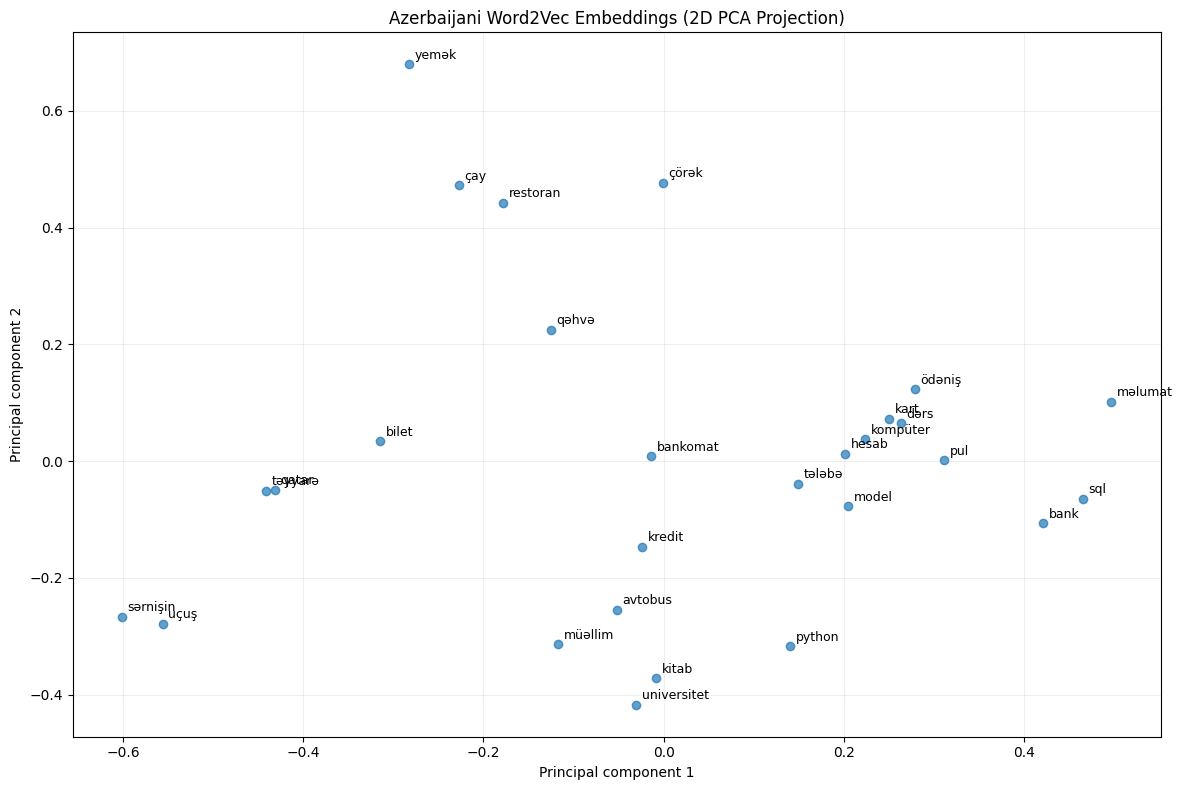

In [15]:
words_to_plot = [
    "bank", "kart", "kredit", "pul", "hesab", "bankomat", "ödəniş",
    "python", "kod", "sql", "model", "məlumat", "kompüter",
    "universitet", "tələbə", "müəllim", "dərs", "kitab",
    "təyyarə", "uçuş", "sərnişin", "avtobus", "qatar", "bilet",
    "çay", "qəhvə", "restoran", "yemək", "çörək",
]
words_to_plot = [w for w in words_to_plot if w in model.wv]
X = np.array([model.wv[w] for w in words_to_plot])
xy = PCA(n_components=2).fit_transform(X)

plt.figure(figsize=(12, 8))
plt.scatter(xy[:, 0], xy[:, 1], alpha=0.7)
for (x, y), w in zip(xy, words_to_plot):
    plt.annotate(w, (x, y), xytext=(4, 4), textcoords="offset points", fontsize=9)
plt.title("Azerbaijani Word2Vec Embeddings (2D PCA Projection)")
plt.xlabel("Principal component 1")
plt.ylabel("Principal component 2")
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

## 11. Save and reload your trained model

Save the whole Gensim model if you want to continue training. For similarity-only use, `model.wv` (KeyedVectors) can also be saved separately.

In [16]:
output_path = Path("azerbaijani_word2vec_demo.model")
model.save(str(output_path))
loaded_model = Word2Vec.load(str(output_path))
print("Saved to:", output_path.resolve())
print("Reloaded vector shape:", loaded_model.wv["bank"].shape)

Saved to: /content/azerbaijani_word2vec_demo.model
Reloaded vector shape: (50,)


## 12. Use your own Azerbaijani corpus

Create a UTF-8 file named **`azerbaijani_corpus.txt`** with one Azerbaijani sentence per line, then run the following cell. If the file is missing, the sample dataset remains in use.

Example file:

```text
Müştəri bank kartını blokladı.
Bank müştərilərə mobil tətbiq təqdim edir.
Kart hesabındakı balans yeniləndi.
```

**Data quality matters:** remove sensitive customer information, deduplicate boilerplate, ensure text rights, and use a diverse corpus. For real use, split data into train/evaluation sets and assess results on domain-specific word pairs or downstream tasks.

In [ ]:
file_path = Path("azerbaijani_corpus.txt")
if file_path.exists():
    custom_lines = [line.strip() for line in file_path.read_text(encoding="utf-8").splitlines()]
    custom_tokens = [tokenize_az(line) for line in custom_lines if line.strip()]
    custom_tokens = [t for t in custom_tokens if len(t) >= 2]
    print("Custom training sentences:", len(custom_tokens))
    if custom_tokens:
        custom_model = Word2Vec(custom_tokens, vector_size=100, window=5,
                                min_count=2, sg=1, negative=10,
                                epochs=15, workers=1, seed=SEED)
        print("Custom vocabulary size:", len(custom_model.wv))
        custom_model.save("azerbaijani_word2vec_custom.model")
    else:
        print("No suitable custom sentences found.")
else:
    print("No custom text file found. Add azerbaijani_corpus.txt to train on your own data.")

## 13. Exercises

1. Change `sg=1` to `sg=0` and compare nearest neighbors for `bank` and `kart`. Which setting looks more sensible for your tiny dataset?
2. Set `vector_size` to 20, then 100. Does a larger vector always give better results?
3. Add **20 original Azerbaijani banking sentences** and retrain the model. What changes?
4. Compare `kart` with `kredit`, then `kart` with `təyyarə`. Are the scores what you expected?
5. Explain why `kart`, `kartı`, and `kartım` are separate entries. What preprocessing could help?

### Note

Word2Vec produces **one static vector per word**, regardless of sentence context. Modern Transformer encoders (for example, BERT-style models) can produce **context-dependent token embeddings** and sentence embeddings.